In [ ]:
%pip -q install rdkit pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 62.3 MB/s eta 0:00:00


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from itertools import product
import hashlib
import json
import shutil
import sys

import pandas as pd
from rdkit import Chem, rdBase
from rdkit.Chem import Draw, rdMolDescriptors
from IPython.display import display
from google.colab import files

# ---------- 1. Load the reviewed reference library ----------

print("Upload Gao2021_reference_library_A1_A12.csv")
uploaded = files.upload()

reference_name = "Gao2021_reference_library_A1_A12.csv"
assert reference_name in uploaded, f"Please upload {reference_name}"

reference = pd.read_csv(reference_name)
assert len(reference) == 12
assert reference["Reference_ID"].is_unique

def canonicalize(smiles):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"Invalid reference SMILES: {smiles}")
    return Chem.MolToSmiles(mol, canonical=True)

reference["Canonical_SMILES"] = reference["SMILES"].map(canonicalize)
assert reference["Canonical_SMILES"].is_unique

reference_lookup = reference.set_index(
    "Canonical_SMILES"
)["Reference_ID"].to_dict()

# ---------- 2. Define the design ----------

# Atom indices depend on this exact parent SMILES.
PARENT_SMILES = "O=C1c2ccccc2-n2c1nc1ccccc1c2=O"
SITE_INDICES = {"C-2": 14, "C-8": 4}

parent = Chem.MolFromSmiles(PARENT_SMILES)
assert parent is not None
assert Chem.MolToInchiKey(parent) == \
    "VQQVWGVXDIPORV-UHFFFAOYSA-N"

parent_canonical = canonicalize(PARENT_SMILES)

# None means leave the parent's hydrogen unchanged.
c2_options = {
    "H": None,
    "F": "F",
    "Br": "Br",
}

# Fragment atom 0 is the attachment atom.
c8_options = {
    "H": None,
    "Br": "Br",
    "I": "I",
    "Cl": "Cl",
    "F": "F",
    "CH3": "C",
    "NO2": "[N+](=O)[O-]",
    "NH2": "N",
    "CF3": "C(F)(F)F",
    "N(CH3)2": "N(C)C",
}

for position, index in SITE_INDICES.items():
    atom = parent.GetAtomWithIdx(index)
    assert atom.GetSymbol() == "C"
    assert atom.GetIsAromatic()
    assert atom.GetTotalNumHs() == 1

run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
out = Path("tryptanthrin_library") / run_id
out.mkdir(parents=True, exist_ok=False)

# Keep the exact reference input used for this run.
reference.to_csv(out / "reference_input.csv", index=False)

rule_rows = []
for site, options in [("C-2", c2_options), ("C-8", c8_options)]:
    for label, fragment in options.items():
        rule_rows.append({
            "Site": site,
            "Parent_atom_index": SITE_INDICES[site],
            "Substituent": label,
            "Fragment_SMILES": fragment or "",
            "Action": "Retain hydrogen" if fragment is None else "Substitute",
            "Evidence": (
                "Individual site/substituent reported in Gao2021; "
                "cross-combinations are exploratory unless reference-matched"
            )
        })

pd.DataFrame(rule_rows).to_csv(
    out / "generation_rules.csv", index=False
)

# ---------- 3. Generate all combinations ----------

raw_rows = []
molecule_lookup = {}
seen = {}

for attempt_number, (c2_label, c8_label) in enumerate(
    product(c2_options, c8_options), start=1
):
    attempt_id = f"ATT_{attempt_number:04d}"

    modified_sites = []
    modifications = []
    for site, label in [("C-2", c2_label), ("C-8", c8_label)]:
        if label != "H":
            modified_sites.append(site)
            modifications.append(f"{site}:{label}")

    record = {
        "Attempt_ID": attempt_id,
        "Analog_ID": "",
        "SMILES": "",
        "InChIKey": "",
        "C2_substituent": c2_label,
        "C8_substituent": c8_label,
        "Modified_site": "; ".join(modified_sites) or "None",
        "Substituent": "; ".join(modifications) or "None",
        "Modification_type": (
            "Unchanged parent" if not modifications
            else "Ring hydrogen substitution"
        ),
        "Molecular_formula": "",
        "Category": "",
        "Matched_reference_ID": "",
        "Validation_status": "FAILED",
        "Exclusion_reason": "",
        "RDKit_version": rdBase.rdkitVersion,
    }

    try:
        molecule = Chem.Mol(parent)

        for site, label, options in [
            ("C-2", c2_label, c2_options),
            ("C-8", c8_label, c8_options),
        ]:
            fragment_smiles = options[label]
            if fragment_smiles is None:
                continue

            fragment = Chem.MolFromSmiles(fragment_smiles)
            if fragment is None:
                raise ValueError(f"Invalid fragment for {site}")

            offset = molecule.GetNumAtoms()
            editable = Chem.RWMol(
                Chem.CombineMols(molecule, fragment)
            )
            editable.AddBond(
                SITE_INDICES[site],
                offset,  # fragment atom 0
                Chem.BondType.SINGLE
            )
            molecule = editable.GetMol()

        Chem.SanitizeMol(molecule)
        smiles = canonicalize(Chem.MolToSmiles(molecule))

        record["SMILES"] = smiles
        record["InChIKey"] = Chem.MolToInchiKey(molecule)
        record["Molecular_formula"] = \
            rdMolDescriptors.CalcMolFormula(molecule)

        if len(Chem.GetMolFrags(molecule)) != 1:
            raise ValueError("Disconnected structure")
        if Chem.GetFormalCharge(molecule) != 0:
            raise ValueError("Unexpected net charge")
        if not molecule.HasSubstructMatch(parent):
            raise ValueError("Parent scaffold not retained")

        if smiles == parent_canonical:
            record["Category"] = "Parent"
        elif smiles in reference_lookup:
            record["Category"] = "Published_reference"
            record["Matched_reference_ID"] = reference_lookup[smiles]
        else:
            record["Category"] = "Exploratory_combination"

        # Stable within the recorded canonicalization/version convention.
        digest = hashlib.sha256(smiles.encode()).hexdigest()[:16]
        record["Analog_ID"] = f"TRY_{digest}"

        if smiles in seen:
            record["Validation_status"] = "DUPLICATE"
            record["Exclusion_reason"] = \
                f"Same structure as {seen[smiles]}"
        else:
            seen[smiles] = attempt_id
            record["Validation_status"] = "PASS"
            molecule_lookup[record["Analog_ID"]] = molecule

    except Exception as error:
        record["Exclusion_reason"] = str(error)

    raw_rows.append(record)

# ---------- 4. Validate and save ----------

raw = pd.DataFrame(raw_rows)
clean = raw.loc[raw["Validation_status"] == "PASS"].copy()

audit = raw[[
    "Attempt_ID", "Analog_ID", "Validation_status", "Exclusion_reason"
]].copy()

summary = pd.DataFrame([{
    "Attempted": len(raw),
    "Failed": int((raw["Validation_status"] == "FAILED").sum()),
    "Duplicates": int((raw["Validation_status"] == "DUPLICATE").sum()),
    "Retained": len(clean),
    "Parent": int((clean["Category"] == "Parent").sum()),
    "Published_references": int(
        (clean["Category"] == "Published_reference").sum()
    ),
    "Exploratory_combinations": int(
        (clean["Category"] == "Exploratory_combination").sum()
    ),
}])

assert len(raw) == 30
assert (
    summary.loc[0, "Failed"]
    + summary.loc[0, "Duplicates"]
    + summary.loc[0, "Retained"]
) == len(raw)
assert clean["Analog_ID"].is_unique
assert clean["SMILES"].is_unique

# Record whether all reviewed references were recovered.
recovered = set(clean["Matched_reference_ID"]) - {""}
missing_references = sorted(
    set(reference["Reference_ID"]) - recovered
)

raw.to_csv(out / "tryptanthrin_analogs_raw.csv", index=False)
clean.to_csv(out / "tryptanthrin_analogs_clean.csv", index=False)
audit.to_csv(out / "validation_audit.csv", index=False)
summary.to_csv(out / "library_statistics.csv", index=False)

# Preserve this ID registry in future expansions; do not renumber it.
clean[["Analog_ID", "SMILES", "InChIKey"]].to_csv(
    out / "analog_id_registry.csv", index=False
)

with Chem.SDWriter(str(out / "tryptanthrin_library.sdf")) as writer:
    for _, row in clean.iterrows():
        mol = Chem.Mol(molecule_lookup[row["Analog_ID"]])
        mol.SetProp("_Name", row["Analog_ID"])
        mol.SetProp("Category", row["Category"])
        mol.SetProp("C2_substituent", row["C2_substituent"])
        mol.SetProp("C8_substituent", row["C8_substituent"])
        writer.write(mol)

# Ten structures per sheet for visual inspection.
for start in range(0, len(clean), 10):
    subset = clean.iloc[start:start + 10]
    grid = Draw.MolsToGridImage(
        [molecule_lookup[x] for x in subset["Analog_ID"]],
        legends=[
            f'C2:{row.C2_substituent}; C8:{row.C8_substituent}'
            for row in subset.itertuples()
        ],
        molsPerRow=2,
        subImgSize=(400, 300),
        useSVG=False,
        returnPNG=False
    )
    grid.save(out / f"structures_{start + 1:02d}_{start + len(subset):02d}.png")

metadata = {
    "Run_UTC": run_id,
    "Python_version": sys.version,
    "RDKit_version": rdBase.rdkitVersion,
    "pandas_version": pd.__version__,
    "Parent_SMILES": PARENT_SMILES,
    "Site_indices": SITE_INDICES,
    "Design": "C2 H/F/Br crossed with ten C8 options",
    "Source_DOI": "10.3390/biomedicines9111527",
    "Missing_reference_IDs": missing_references,
    "Manual_grid_review": "PENDING",
    "Limitations": [
        "Cross-combinations are exploratory design hypotheses.",
        "Reference matching covers this supplied 12-compound set only.",
        "Novelty, activity and synthetic feasibility are not established.",
        "Retain the ID registry if software or standardization changes."
    ]
}
(out / "run_metadata.json").write_text(
    json.dumps(metadata, indent=2), encoding="utf-8"
)

display(summary)
print("Missing reviewed references:", missing_references)
print("Inspect all three saved structure grids before downstream use.")

archive = shutil.make_archive(
    f"/content/tryptanthrin_library_{run_id}",
    "zip",
    root_dir=str(out)
)
files.download(archive)

Upload Gao2021_reference_library_A1_A12.csv


Saving Gao2021_reference_library_A1_A12.csv to Gao2021_reference_library_A1_A12.csv


,Attempted,Failed,Duplicates,Retained,Parent,Published_references,Exploratory_combinations
0,30,0,0,30,1,12,17


Missing reviewed references: []
Inspect all three saved structure grids before downstream use.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Upload 9935993.zip


Saving 9935993.zip to 9935993.zip


,Reference_ID,Mapped_substituents,Molecular_formula,Validation_status,Reason
0,Yang2019_5a,C-2: ring-C-N; C-8: ring-F,C21H19FN4O2,PASS,
1,Yang2019_5b,C-2: ring-C-N; C-8: ring-F,C20H17FN4O2,PASS,
2,Yang2019_5c,C-2: ring-C-N; C-8: ring-F,C25H25FN4O4,PASS,
3,Yang2019_5d,C-2: ring-C-N,C21H20N4O2,PASS,
4,Yang2019_5e,C-2: ring-C-N; C-8: ring-F,C18H14FN3O2,PASS,
5,Yang2019_5f,C-2: ring-C-N; C-8: ring-F,C20H16FN3O3,PASS,
6,Yang2019_9a,C-2: direct ring-N; C-8: ring-F,C20H17FN4O2,PASS,
7,Yang2019_9b,C-2: direct ring-N; C-8: ring-F,C19H15FN4O2,PASS,
8,Yang2019_9c,C-2: direct ring-N; C-8: ring-F,C20H16FN3O2,PASS,
9,Yang2019_9d,C-2: direct ring-N,C20H18N4O2,PASS,


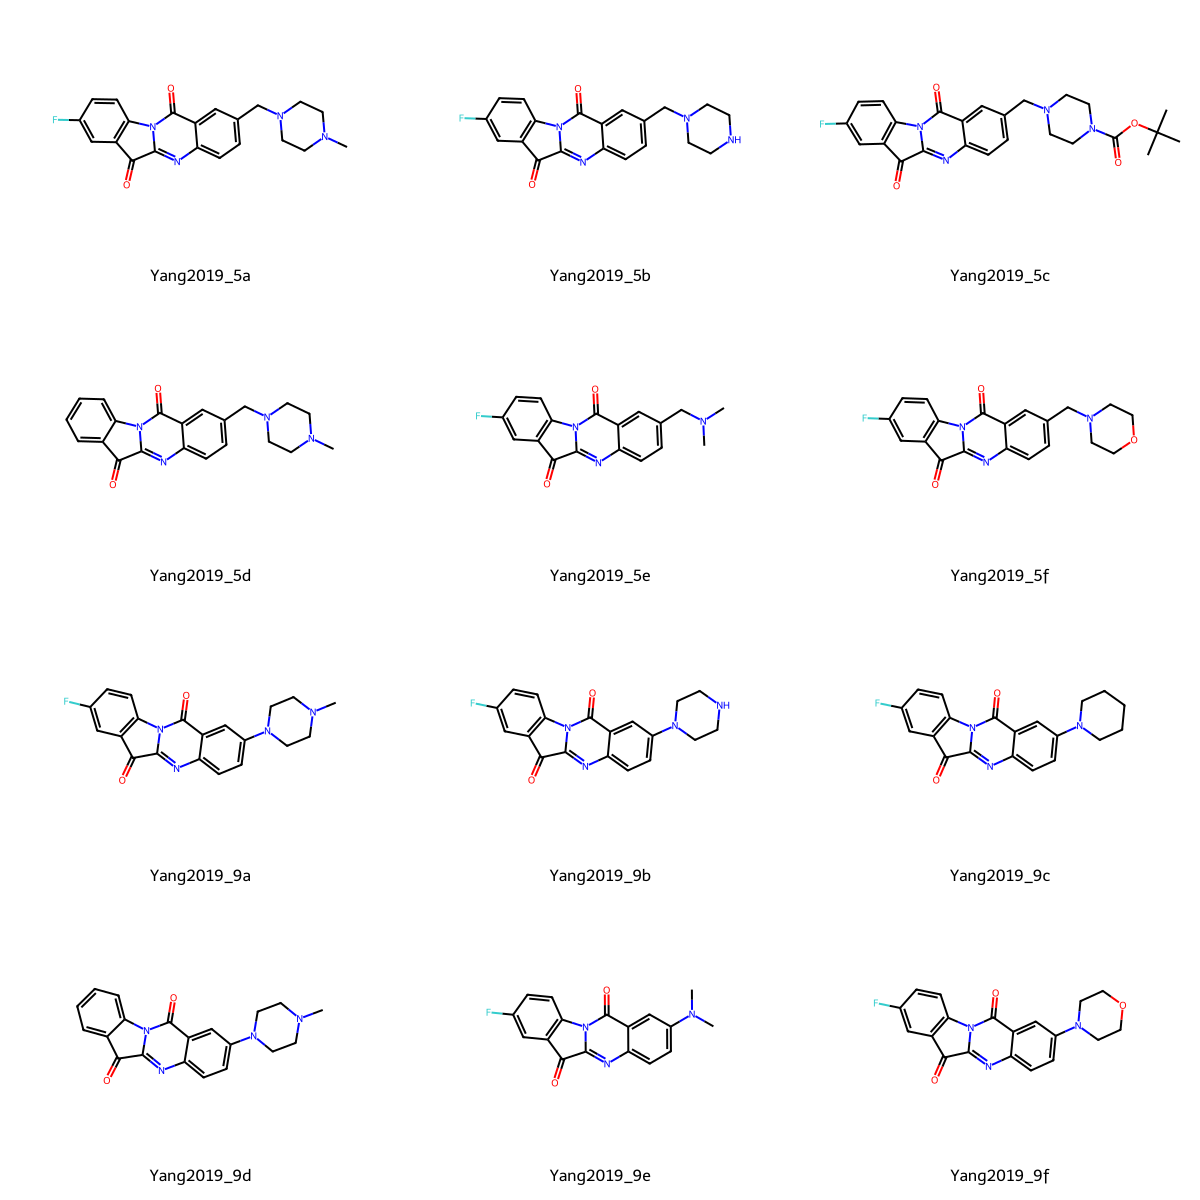

Passed: 12 / 12


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
import csv
import io
import zipfile
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw, rdMolDescriptors
from IPython.display import display
from google.colab import files

print("Upload 9935993.zip")
uploaded = files.upload()

zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
assert len(zip_names) == 1, "Upload only the Yang2019 ZIP."

with zipfile.ZipFile(io.BytesIO(uploaded[zip_names[0]])) as archive:
    csv_names = [
        name for name in archive.namelist()
        if name.lower().endswith(".csv")
    ]
    assert len(csv_names) == 1
    # The chemical structure fields are ASCII; preserve activity data separately.
    text = archive.read(csv_names[0]).decode("cp1252")

parent = Chem.MolFromSmiles(
    "O=C1c2ccccc2-n2c1nc1ccccc1c2=O"
)

# Chemical positions mapped to indices in this exact parent.
positions = {
    15: "C-1", 14: "C-2", 13: "C-3", 12: "C-4",
    3: "C-7", 4: "C-8", 5: "C-9", 6: "C-10"
}

expected_ids = {
    "5a", "5b", "5c", "5d", "5e", "5f",
    "9a", "9b", "9c", "9d", "9e", "9f"
}

records, molecules, legends = [], [], []

for row in csv.reader(io.StringIO(text)):
    if not row or row[0].strip() not in expected_ids:
        continue

    compound_id = row[0].strip()
    source_smiles = row[1].strip()
    record = {
        "Reference_ID": f"Yang2019_{compound_id}",
        "Source_SMILES": source_smiles,
        "SMILES": "",
        "InChIKey": "",
        "Molecular_formula": "",
        "Mapped_substituents": "",
        "Source_DOI": "10.1021/acs.jmedchem.9b01079",
        "Validation_status": "FAILED",
        "Reason": ""
    }

    try:
        mol = Chem.MolFromSmiles(source_smiles)
        if mol is None:
            raise ValueError("SMILES parsing failed.")

        Chem.SanitizeMol(mol)

        if len(Chem.GetMolFrags(mol)) != 1:
            raise ValueError("Disconnected structure.")
        if Chem.GetFormalCharge(mol) != 0:
            raise ValueError("Unexpected net formal charge.")

        match = mol.GetSubstructMatch(parent)
        if not match:
            raise ValueError("Exact parent scaffold not found.")

        core_atoms = set(match)
        attachments = []

        for parent_index, site_name in positions.items():
            atom = mol.GetAtomWithIdx(match[parent_index])

            for neighbor in atom.GetNeighbors():
                if neighbor.GetIdx() in core_atoms:
                    continue

                symbol = neighbor.GetSymbol()

                # Distinguish direct aryl–N from aryl–CH2–N.
                if symbol == "N":
                    linkage = "direct ring-N"
                elif symbol == "C" and any(
                    other.GetSymbol() == "N"
                    for other in neighbor.GetNeighbors()
                    if other.GetIdx() != atom.GetIdx()
                ):
                    linkage = "ring-C-N"
                else:
                    linkage = f"ring-{symbol}"

                attachments.append(f"{site_name}: {linkage}")

        record.update({
            "SMILES": Chem.MolToSmiles(mol, canonical=True),
            "InChIKey": Chem.MolToInchiKey(mol),
            "Molecular_formula": rdMolDescriptors.CalcMolFormula(mol),
            "Mapped_substituents": "; ".join(attachments),
            "Validation_status": "PASS"
        })

        molecules.append(mol)
        legends.append(record["Reference_ID"])

    except Exception as error:
        record["Reason"] = str(error)

    records.append(record)

results = pd.DataFrame(records)

assert len(results) == 12, "Expected 12 compound records."
assert results["Reference_ID"].is_unique

passed = results.loc[results["Validation_status"] == "PASS"]
assert passed["SMILES"].is_unique, "Duplicate reference structures."

display(results[[
    "Reference_ID", "Mapped_substituents",
    "Molecular_formula", "Validation_status", "Reason"
]])

if molecules:
    display(Draw.MolsToGridImage(
        molecules,
        legends=legends,
        molsPerRow=3,
        subImgSize=(400, 300)
    ))

print("Passed:", len(passed), "/ 12")

filename = "Yang2019_reference_validation.csv"
results.to_csv(filename, index=False)
files.download(filename)